# Titulo

In [32]:
import sys
!{sys.executable} -m pip install GPy

You should consider upgrading via the 'c:\Users\aeagu\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [5]:
import pandas as pd
import numpy as np
import GPy

In [7]:
epm = pd.read_csv("data/EPMDATA_INTERPOLATED_v2.csv", parse_dates=['date'])
epm.columns

Index(['date', 'Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)',
       'Sensor 4 (10m)'],
      dtype='object')

In [5]:
print("Valores unicos del Sensor 1 (5m)", len(epm['Sensor 1 (5m)'].unique()), f"de {len(epm['Sensor 1 (5m)'])}")
print("Valores unicos del Sensor 2 (10m)", len(epm['Sensor 2 (10m)'].unique()), f"de {len(epm['Sensor 2 (10m)'])}")
print("Valores unicos del Sensor 3 (5m)", len(epm['Sensor 3 (5m)'].unique()), f"de {len(epm['Sensor 3 (5m)'])}")
print("Valores unicos del Sensor 4 (10m)", len(epm['Sensor 4 (10m)'].unique()), f"de {len(epm['Sensor 4 (10m)'])}")

Valores unicos del Sensor 1 (5m) 19 de 885
Valores unicos del Sensor 2 (10m) 45 de 885
Valores unicos del Sensor 3 (5m) 25 de 885
Valores unicos del Sensor 4 (10m) 10 de 885


# Generación de GP lineal

RMSE: 2.4185 mm
MAE:  2.1157 mm
Cobertura intervalo 95%: 95.6%


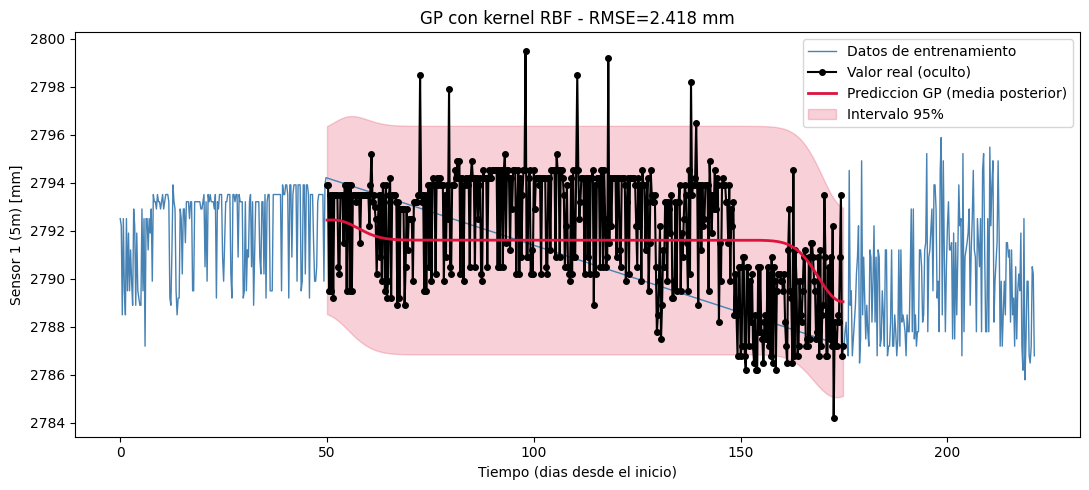

In [9]:
#Seleccion de la serie
serie = 'Sensor 2 (10m)'
y = epm[serie].values
t = (epm["date"]-epm["date"].min()).dt.total_seconds().values / 3600

#Normalizo los datos de la serie de tiempo
y_mean, y_std = y.mean(), y.std()
y_norm = (y - y_mean) / y_std

#<Defino los criterios de la mascara para la venta sin datos
gap_start = 200 
gap_len = 500
mask_hidden = np.zeros(len(y_norm), dtype=bool)
mask_hidden[gap_start:gap_start+gap_len] = True

#Defino el conjunto de entrenamiento
t_train = t[~mask_hidden].reshape(-1,1)
y_train = y_norm[~mask_hidden].reshape(-1,1)

#Corro el GP
kernel = GPy.kern.RBF(input_dim=1, variance=1.0, lengthscale=100.0)
#kernel.lengthscale.fix()
modelo = GPy.models.GPRegression(t_train, y_train, kernel)
modelo.optimize(messages=False)

#-----------------------------------------------------------------
#Extraigo los puntos de la brecha (los que oculté) para comparar contra la prediccion
t_hidden = t[mask_hidden].reshape(-1,1)
y_hidden_true = y_norm[mask_hidden]   # valor real (normalizado), que el modelo NO vio

#Prediccion del GP sobre la brecha: media posterior y varianza posterior
y_pred_norm, y_var_norm = modelo.predict(t_hidden)
y_pred_norm = y_pred_norm.flatten()
y_std_pred_norm = np.sqrt(y_var_norm.flatten())

#Devuelvo todo a la escala original (mm), usando el mismo y_mean/y_std con que normalice
y_pred_mm = y_pred_norm * y_std + y_mean
y_hidden_true_mm = y_hidden_true * y_std + y_mean
y_std_pred_mm = y_std_pred_norm * y_std   # ojo: la desviacion NO lleva +y_mean, solo se escala

#Metricas de error en mm
rmse = np.sqrt(np.mean((y_pred_mm - y_hidden_true_mm)**2))
mae = np.mean(np.abs(y_pred_mm - y_hidden_true_mm))
print(f"RMSE: {rmse:.4f} mm")
print(f"MAE:  {mae:.4f} mm")

#Cobertura del intervalo de confianza al 95%
z95_lo = y_pred_mm - 1.96*y_std_pred_mm
z95_hi = y_pred_mm + 1.96*y_std_pred_mm
cobertura = np.mean((y_hidden_true_mm >= z95_lo) & (y_hidden_true_mm <= z95_hi))
print(f"Cobertura intervalo 95%: {cobertura*100:.1f}%")

#Grafico
import matplotlib.pyplot as plt

t_dias = t/24  # paso de horas a dias, solo para que el eje x sea mas legible

fig, ax = plt.subplots(figsize=(11,5))
ax.plot(t_dias[~mask_hidden], y[~mask_hidden], '-', color='steelblue', linewidth=1, label='Datos de entrenamiento')
ax.plot(t_dias[mask_hidden], y[mask_hidden], '-o', color='black', linewidth=1.5, markersize=4, label='Valor real (oculto)')
ax.plot(t_dias[mask_hidden], y_pred_mm, '-', color='crimson', linewidth=2, label='Prediccion GP (media posterior)')
ax.fill_between(t_dias[mask_hidden], z95_lo, z95_hi, color='crimson', alpha=0.2, label='Intervalo 95%')
ax.set_xlabel('Tiempo (dias desde el inicio)')
ax.set_ylabel('Sensor 1 (5m) [mm]')
ax.set_title(f'GP con kernel RBF - RMSE={rmse:.3f} mm')
ax.legend()
plt.tight_layout()
plt.show()

## Con kernel Matérn

  Mat52.       |                value  |  constraints  |  priors
  variance     |  0.42265269396188043  |      +ve      |        
  lengthscale  |   228.79459148289445  |      +ve      |        
RMSE: 1.7517 mm
MAE:  1.4513 mm
Cobertura intervalo 95%: 99.0%


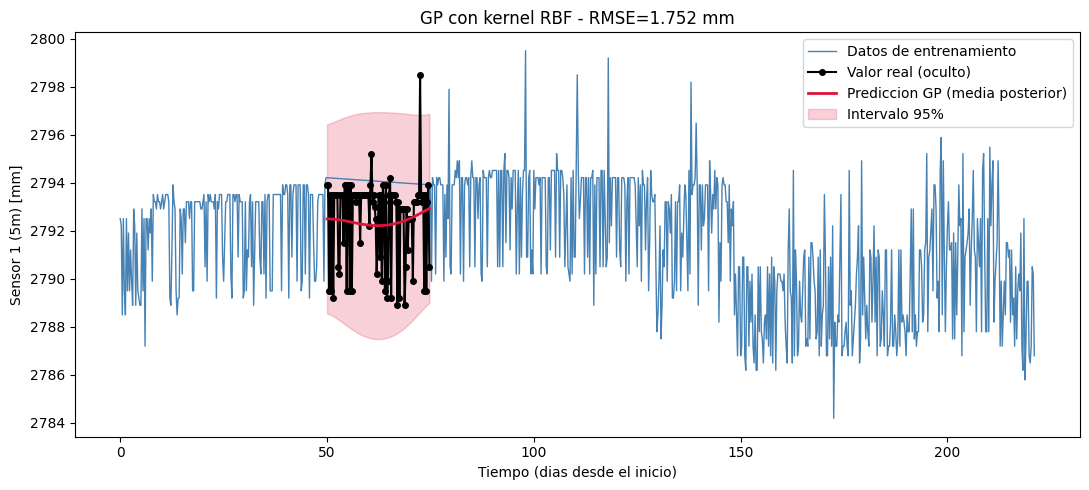

In [36]:
#kernel = GPy.kern.Matern32(input_dim=1, variance=1.0, lengthscale=10.0)
kernel = GPy.kern.Matern52(input_dim=1, variance=1.0, lengthscale=10.0)
#kernel = GPy.kern.OU(input_dim=1, variance=1.0, lengthscale=10.0)   # Matern 1/2

modelo = GPy.models.GPRegression(t_train, y_train, kernel)
modelo.optimize(messages=False)
print(modelo.kern)
#-----------------------------------------------------------------
#Extraigo los puntos de la brecha (los que oculté) para comparar contra la prediccion
t_hidden = t[mask_hidden].reshape(-1,1)
y_hidden_true = y_norm[mask_hidden]   # valor real (normalizado), que el modelo NO vio

#Prediccion del GP sobre la brecha: media posterior y varianza posterior
y_pred_norm, y_var_norm = modelo.predict(t_hidden)
y_pred_norm = y_pred_norm.flatten()
y_std_pred_norm = np.sqrt(y_var_norm.flatten())

#Devuelvo todo a la escala original (mm), usando el mismo y_mean/y_std con que normalice
y_pred_mm = y_pred_norm * y_std + y_mean
y_hidden_true_mm = y_hidden_true * y_std + y_mean
y_std_pred_mm = y_std_pred_norm * y_std   # ojo: la desviacion NO lleva +y_mean, solo se escala

#Metricas de error en mm
rmse = np.sqrt(np.mean((y_pred_mm - y_hidden_true_mm)**2))
mae = np.mean(np.abs(y_pred_mm - y_hidden_true_mm))
print(f"RMSE: {rmse:.4f} mm")
print(f"MAE:  {mae:.4f} mm")

#Cobertura del intervalo de confianza al 95%
z95_lo = y_pred_mm - 1.96*y_std_pred_mm
z95_hi = y_pred_mm + 1.96*y_std_pred_mm
cobertura = np.mean((y_hidden_true_mm >= z95_lo) & (y_hidden_true_mm <= z95_hi))
print(f"Cobertura intervalo 95%: {cobertura*100:.1f}%")

#Grafico
import matplotlib.pyplot as plt

t_dias = t/24  # paso de horas a dias, solo para que el eje x sea mas legible

fig, ax = plt.subplots(figsize=(11,5))
ax.plot(t_dias[~mask_hidden], y[~mask_hidden], '-', color='steelblue', linewidth=1, label='Datos de entrenamiento')
ax.plot(t_dias[mask_hidden], y[mask_hidden], '-o', color='black', linewidth=1.5, markersize=4, label='Valor real (oculto)')
ax.plot(t_dias[mask_hidden], y_pred_mm, '-', color='crimson', linewidth=2, label='Prediccion GP (media posterior)')
ax.fill_between(t_dias[mask_hidden], z95_lo, z95_hi, color='crimson', alpha=0.2, label='Intervalo 95%')
ax.set_xlabel('Tiempo (dias desde el inicio)')
ax.set_ylabel('Sensor 1 (5m) [mm]')
ax.set_title(f'GP con kernel RBF - RMSE={rmse:.3f} mm')
ax.legend()
plt.tight_layout()
plt.show()

# CCM — selección del par TPM-EPM para el Paso 2 del MOGP

Esta sección adapta el análisis de Convergent Cross Mapping (CCM) que ya se había corrido en `tpm y ccm.ipynb` (la sección `#CCM` de ese cuaderno), pero usando los archivos de datos locales de este proyecto (`data/EPMDATA_INTERPOLATED_v2.csv`, `data/TPMDATA_CLEANED.csv`) en vez de las rutas de Google Drive del cuaderno original.

**Objetivo:** identificar, para EPM Sensor 1 (5m), cuál de las 14 series TPM (POT(1..7), Tilt(1..7)) tiene mayor CCM skill hacia él. Ese par es el que `funciones_vector_valuadas.md` (sección 6) pide usar como el caso $D=2$ del Paso 2 del ablation study (MOGP-ICM).

**Nota importante sobre alineación temporal:** a diferencia del MOGP (que maneja datos heterotópicos de forma nativa y por eso NO se sincronizan artificialmente los relojes de EPM y TPM — ver sección 5 del documento), el método CCM sí necesita que ambas series compartan una única rejilla temporal para construir el espacio de estados. Por eso, y solo para este análisis, se alinea TPM sobre la rejilla de EPM (desfase estructural constante de 1h entre ambos). Esta alineación no se usa en el entrenamiento del MOGP.

In [10]:
import sys
!{sys.executable} -m pip install pyEDM

You should consider upgrading via the 'c:\Users\aeagu\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [3]:
import pyEDM
from itertools import product

In [8]:
#TPM no se había cargado todavía en este notebook (solo se cargó EPM en la Celda 3)
tpm = pd.read_csv("data/TPMDATA_CLEANED.csv", parse_dates=['date'])

#Alineo TPM sobre la rejilla de EPM solo para el CCM (ver nota de la celda markdown anterior).
#'freq' no es una serie de deformación/inclinación, se descarta antes de construir el dataframe del CCM.
df_ccm = pd.merge_asof(
    epm.sort_values('date'),
    tpm.drop(columns=['freq']).sort_values('date'),
    on='date',
    direction='nearest',
    tolerance=pd.Timedelta('3h'),
)
df_ccm = df_ccm.dropna().reset_index(drop=True)

#pyEDM (2.5.7) no maneja bien una columna datetime64[ns] como parte del dataFrame
#(revienta con "Cannot convert from specific units to generic units in NumPy
#datetimes or timedeltas"). La descartamos aqui -- igual que hacia tpm y ccm.ipynb
#con epm.drop(columns=["date"]) -- y dejamos que pyEDM use el indice posicional (fila)
#como eje temporal, que es justo lo que esperan los rangos "1 600" de lib/pred.
df_ccm = df_ccm.drop(columns=['date'])

print(f"Filas EPM: {len(epm)}, filas TPM: {len(tpm)}, filas alineadas para CCM: {len(df_ccm)}")

Filas EPM: 885, filas TPM: 884, filas alineadas para CCM: 884


In [9]:
#Optimización de la dimensión de embebido E para cada una de las 18 series (igual que en tpm y ccm.ipynb)
columnas_tpm_epm = ['POT(1)','POT(2)','POT(3)','POT(4)','POT(5)','POT(6)','POT(7)',
                     'Tilt(1)','Tilt(2)','Tilt(3)','Tilt(4)','Tilt(5)','Tilt(6)','Tilt(7)',
                     'Sensor 1 (5m)','Sensor 2 (10m)','Sensor 3 (5m)','Sensor 4 (10m)']

n = len(df_ccm)
lib_end = int(n * 0.68)          #misma proporción lib/pred que usaba tpm y ccm.ipynb (600/881), adaptada a n filas
lib_range = f"1 {lib_end}"
pred_range = f"{lib_end + 1} {n}"
maxE = 40    # mismo maxE para todas, para que la tabla sea comparable

tabla_E = []

for col in columnas_tpm_epm:
    resultado = pyEDM.EmbedDimension(
        dataFrame = df_ccm,
        lib     = lib_range,
        pred    = pred_range,
        maxE    = maxE,
        columns = [col],
        target  = [col],
        showPlot = False   # apaga el gráfico automático, ya vamos a tabular
    )
    E_optimo = resultado.loc[resultado['rho'].idxmax(), 'E']
    rho_max  = resultado['rho'].max()
    tabla_E.append({'serie': col, 'E_optimo': E_optimo, 'rho_max': rho_max})

tabla_E = pd.DataFrame(tabla_E)
print(tabla_E)

             serie  E_optimo   rho_max
0           POT(1)         5  0.733586
1           POT(2)         2  0.984460
2           POT(3)         8  0.659151
3           POT(4)         8  0.903181
4           POT(5)         2  0.979697
5           POT(6)         9  0.801956
6           POT(7)         4  0.817897
7          Tilt(1)        34  0.423229
8          Tilt(2)        38  0.457165
9          Tilt(3)        21  0.360616
10         Tilt(4)         8  0.430643
11         Tilt(5)         4  0.522726
12         Tilt(6)         5  0.677428
13         Tilt(7)        12  0.432897
14   Sensor 1 (5m)        26  0.393980
15  Sensor 2 (10m)        17  0.337922
16   Sensor 3 (5m)        36  0.360861
17  Sensor 4 (10m)        14  0.717403


In [10]:
#CCM para los 56 pares TPM-EPM (igual estructura que tpm y ccm.ipynb, pero sin
#reusar los nombres 'tpm'/'epm' como variables de loop -- en el cuaderno original
#el for sobreescribía los DataFrames tpm/epm con strings dentro del propio loop).
E_optimo = tabla_E.set_index('serie')['E_optimo'].to_dict()

series_tpm = ['POT(1)','POT(2)','POT(3)','POT(4)','POT(5)','POT(6)','POT(7)',
              'Tilt(1)','Tilt(2)','Tilt(3)','Tilt(4)','Tilt(5)','Tilt(6)','Tilt(7)']
series_epm = ['Sensor 1 (5m)','Sensor 2 (10m)','Sensor 3 (5m)','Sensor 4 (10m)']

sample = 100
exclusionRadius = 10       # provisional, igual que en tpm y ccm.ipynb

resultados_ccm = {}
pares = list(product(series_tpm, series_epm))

for i, (tpm_col, epm_col) in enumerate(pares):
    print(f"[{i+1}/{len(pares)}] {tpm_col} vs {epm_col}...", flush=True)
    E_par = max(E_optimo[tpm_col], E_optimo[epm_col])

    # el arranque de la librería debe ser mayor que E_par;
    # dejamos un margen de +10 para que el primer punto no sea al filo del mínimo
    inicio = E_par + 10
    libSizes_par = f"{inicio} {n} 40"

    res = pyEDM.CCM(
        dataFrame = df_ccm,
        E = E_par,
        columns = [tpm_col],
        target  = [epm_col],
        libSizes = libSizes_par,
        sample = sample,
        exclusionRadius = exclusionRadius,
        showPlot = False,
        parallel = False   # parallel=True (default) crea un multiprocessing.Pool por cada
                            # una de las 56 llamadas; en Windows eso acumula manejadores sin
                            # liberarse bien y ya hizo que el sistema se quedara sin memoria
                            # a mitad de la corrida. Sin paralelismo es un poco mas lento por
                            # llamada pero estable en las 56 iteraciones.
    )
    resultados_ccm[(tpm_col, epm_col)] = res

resumen = []
for (tpm_col, epm_col), res in resultados_ccm.items():
    res_sorted = res.sort_values('LibSize')
    fila_final = res_sorted.iloc[-1]
    col_tpm_a_epm = res.columns[1]
    col_epm_a_tpm = res.columns[2]

    resumen.append({
        'TPM': tpm_col,
        'EPM': epm_col,
        'E_par': max(E_optimo[tpm_col], E_optimo[epm_col]),
        'libSize_inicio': max(E_optimo[tpm_col], E_optimo[epm_col]) + 10,
        'skill_TPMmanifold_predice_EPM': fila_final[col_tpm_a_epm],
        'skill_EPMmanifold_predice_TPM': fila_final[col_epm_a_tpm],
    })

resumen_df = pd.DataFrame(resumen)
print(resumen_df.sort_values('skill_TPMmanifold_predice_EPM', ascending=False))

[1/56] POT(1) vs Sensor 1 (5m)...
[2/56] POT(1) vs Sensor 2 (10m)...
[3/56] POT(1) vs Sensor 3 (5m)...
[4/56] POT(1) vs Sensor 4 (10m)...
[5/56] POT(2) vs Sensor 1 (5m)...
[6/56] POT(2) vs Sensor 2 (10m)...
[7/56] POT(2) vs Sensor 3 (5m)...
[8/56] POT(2) vs Sensor 4 (10m)...
[9/56] POT(3) vs Sensor 1 (5m)...
[10/56] POT(3) vs Sensor 2 (10m)...
[11/56] POT(3) vs Sensor 3 (5m)...
[12/56] POT(3) vs Sensor 4 (10m)...
[13/56] POT(4) vs Sensor 1 (5m)...
[14/56] POT(4) vs Sensor 2 (10m)...
[15/56] POT(4) vs Sensor 3 (5m)...
[16/56] POT(4) vs Sensor 4 (10m)...
[17/56] POT(5) vs Sensor 1 (5m)...
[18/56] POT(5) vs Sensor 2 (10m)...
[19/56] POT(5) vs Sensor 3 (5m)...
[20/56] POT(5) vs Sensor 4 (10m)...
[21/56] POT(6) vs Sensor 1 (5m)...
[22/56] POT(6) vs Sensor 2 (10m)...
[23/56] POT(6) vs Sensor 3 (5m)...
[24/56] POT(6) vs Sensor 4 (10m)...
[25/56] POT(7) vs Sensor 1 (5m)...
[26/56] POT(7) vs Sensor 2 (10m)...
[27/56] POT(7) vs Sensor 3 (5m)...
[28/56] POT(7) vs Sensor 4 (10m)...
[29/56] Tilt(1)

In [11]:
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
print(resumen_df.round(3).sort_values('skill_TPMmanifold_predice_EPM', ascending=False))

        TPM             EPM  E_par  libSize_inicio  skill_TPMmanifold_predice_EPM  skill_EPMmanifold_predice_TPM
0    POT(1)   Sensor 1 (5m)     26              36                          0.898                          0.824
40  Tilt(4)   Sensor 1 (5m)     26              36                          0.896                          0.676
28  Tilt(1)   Sensor 1 (5m)     34              44                          0.884                          0.845
48  Tilt(6)   Sensor 1 (5m)     26              36                          0.846                          0.754
8    POT(3)   Sensor 1 (5m)     26              36                          0.831                          0.913
24   POT(7)   Sensor 1 (5m)     26              36                          0.819                          0.736
36  Tilt(3)   Sensor 1 (5m)     26              36                          0.799                          0.539
52  Tilt(7)   Sensor 1 (5m)     26              36                          0.773               

### Convergencia y significancia estadística: ¿cuándo un valor de CCM es "alto"?

El ρ del CCM (`skill_TPMmanifold_predice_EPM` / `skill_EPMmanifold_predice_TPM`) **no tiene una escala fija de alto/medio/bajo** — es un coeficiente de correlación entre valores observados y predichos fuera de muestra, y su magnitud sola no dice si el acoplamiento es real. En la literatura de EDM (Sugihara et al. 2012) un valor de CCM se juzga por dos criterios, no por su tamaño:

1. **Convergencia** (`delta_rho_TPMaEPM`, `delta_rho_EPMaTPM`): ¿sube ρ a medida que crece el tamaño de la librería? `delta_rho = ρ(libSize máximo) - ρ(libSize mínimo)`, calculado de la curva completa que ya produjo el CCM principal (celda anterior). Si `delta_rho <= 0`, el skill no mejora con más datos y no hay base para tratarlo como señal real, sin importar qué tan alto se vea el número puntual.

2. **Significancia estadística** (`p_valor_TPMaEPM`, `p_valor_EPMaTPM`, con sus umbrales): el mismo método de surrogates que ya se usó para Transfer Entropy en `tpm y ccm.ipynb` — se permuta la serie que provee el manifold predictor (destruyendo su relación temporal con la otra serie, conservando su distribución), se recalcula el CCM en el tamaño de librería máximo varias veces, y se compara el valor observado contra el percentil 95 de esa distribución nula. `p_valor < 0.05` significa que el valor observado es estadísticamente distinguible del azar.

**Regla práctica para leer los resultados:**
- **Significativo (p<0.05) Y convergente (delta_rho>0)** → evidencia real de acoplamiento (lo más cercano a "alto" que se puede afirmar con rigor).
- **Significativo pero no convergente** → evidencia débil/dudosa, puede ser correlación espúria de muestra finita.
- **No significativo** → sin evidencia de acoplamiento, sin importar qué tan grande se vea el ρ puntual ("bajo", aunque el número no lo parezca).

In [36]:
#Verifico convergencia de cada par con la curva completa que ya calculo el CCM principal
#(criterio de Sugihara et al. 2012: el skill debe SUBIR con el tamaño de librería, no solo
#ser alto en un punto). delta_rho > 0 es la señal esperada de un acoplamiento real.
convergencia = []
for (tpm_col, epm_col), res in resultados_ccm.items():
    res_sorted = res.sort_values('LibSize')
    col_tpm_a_epm = res.columns[1]
    col_epm_a_tpm = res.columns[2]

    convergencia.append({
        'TPM': tpm_col,
        'EPM': epm_col,
        'delta_rho_TPMaEPM': res_sorted.iloc[-1][col_tpm_a_epm] - res_sorted.iloc[0][col_tpm_a_epm],
        'delta_rho_EPMaTPM': res_sorted.iloc[-1][col_epm_a_tpm] - res_sorted.iloc[0][col_epm_a_tpm],
    })

convergencia_df = pd.DataFrame(convergencia)
resumen_df = resumen_df.merge(convergencia_df, on=['TPM', 'EPM'])
print(resumen_df[['TPM', 'EPM', 'delta_rho_TPMaEPM', 'delta_rho_EPMaTPM']]
      .sort_values('delta_rho_TPMaEPM', ascending=False))

        TPM             EPM  delta_rho_TPMaEPM  delta_rho_EPMaTPM
46  Tilt(5)   Sensor 3 (5m)           0.286050           0.224990
37  Tilt(3)  Sensor 2 (10m)           0.260484           0.117093
35  Tilt(2)  Sensor 4 (10m)           0.218227          -0.003777
53  Tilt(7)  Sensor 2 (10m)           0.204353           0.281074
44  Tilt(5)   Sensor 1 (5m)           0.190133           0.261673
41  Tilt(4)  Sensor 2 (10m)           0.161852           0.068590
47  Tilt(5)  Sensor 4 (10m)           0.136064           0.166344
49  Tilt(6)  Sensor 2 (10m)           0.127460           0.265958
31  Tilt(1)  Sensor 4 (10m)           0.125287           0.096590
1    POT(1)  Sensor 2 (10m)           0.117989           0.163414
27   POT(7)  Sensor 4 (10m)           0.116844           0.006981
22   POT(6)   Sensor 3 (5m)           0.100757          -0.117049
43  Tilt(4)  Sensor 4 (10m)           0.098523           0.098012
21   POT(6)  Sensor 2 (10m)           0.098394          -0.021274
5    POT(2

In [1]:
#Test de significancia estadística (surrogates) para el CCM -- mismo método que ya se usó
#para Transfer Entropy en tpm y ccm.ipynb: se permuta la variable que provee el manifold
#predictor (destruyendo su relación temporal con la otra serie pero conservando su
#distribución), se recalcula el CCM en el tamaño de librería máximo N_PERMUTACIONES veces,
#y se compara el skill observado contra el percentil 95 de esa distribución nula.
#
#ADVERTENCIA DE COSTO: esto corre 2 x N_PERMUTACIONES x 56 llamadas a pyEDM.CCM.
#Con N_PERMUTACIONES=99 y sample=30 (reducido SOLO para los surrogates -- el CCM
#principal de arriba ya usó sample=100 para el valor puntual) tarda ~2.5 horas.
N_PERMUTACIONES = 99
SAMPLE_SURROGATE = 30
libSize_max_str = f"{n} {n} 1"   # una sola corrida en el tamaño de librería más grande, no la curva completa

rng = np.random.default_rng(42)
surrogate_stats = []

for i, (tpm_col, epm_col) in enumerate(pares):
    print(f"[{i+1}/{len(pares)}] surrogates {tpm_col} vs {epm_col}...", flush=True)
    E_par = max(E_optimo[tpm_col], E_optimo[epm_col])

    skill_obs_tpm_a_epm = resumen_df.loc[
        (resumen_df['TPM'] == tpm_col) & (resumen_df['EPM'] == epm_col),
        'skill_TPMmanifold_predice_EPM'
    ].iloc[0]
    skill_obs_epm_a_tpm = resumen_df.loc[
        (resumen_df['TPM'] == tpm_col) & (resumen_df['EPM'] == epm_col),
        'skill_EPMmanifold_predice_TPM'
    ].iloc[0]

    #Nulo para "TPM predice EPM": se permuta la serie TPM (la que provee el manifold en esta direccion)
    df_perm = df_ccm.copy()
    null_tpm_a_epm = []
    for _ in range(N_PERMUTACIONES):
        df_perm[tpm_col] = rng.permutation(df_ccm[tpm_col].values)
        res_null = pyEDM.CCM(
            dataFrame=df_perm, E=E_par, columns=[tpm_col], target=[epm_col],
            libSizes=libSize_max_str, sample=SAMPLE_SURROGATE,
            exclusionRadius=exclusionRadius, showPlot=False, parallel=False
        )
        null_tpm_a_epm.append(res_null.iloc[0][f'{tpm_col}:{epm_col}'])

    #Nulo para "EPM predice TPM": se permuta la serie EPM (la que provee el manifold en esta direccion)
    df_perm2 = df_ccm.copy()
    null_epm_a_tpm = []
    for _ in range(N_PERMUTACIONES):
        df_perm2[epm_col] = rng.permutation(df_ccm[epm_col].values)
        res_null2 = pyEDM.CCM(
            dataFrame=df_perm2, E=E_par, columns=[tpm_col], target=[epm_col],
            libSizes=libSize_max_str, sample=SAMPLE_SURROGATE,
            exclusionRadius=exclusionRadius, showPlot=False, parallel=False
        )
        null_epm_a_tpm.append(res_null2.iloc[0][f'{epm_col}:{tpm_col}'])

    surrogate_stats.append({
        'TPM': tpm_col,
        'EPM': epm_col,
        'umbral_TPMaEPM': np.percentile(null_tpm_a_epm, 95),
        'p_valor_TPMaEPM': np.mean(np.array(null_tpm_a_epm) >= skill_obs_tpm_a_epm),
        'umbral_EPMaTPM': np.percentile(null_epm_a_tpm, 95),
        'p_valor_EPMaTPM': np.mean(np.array(null_epm_a_tpm) >= skill_obs_epm_a_tpm),
    })

surrogate_df = pd.DataFrame(surrogate_stats)
resumen_df = resumen_df.merge(surrogate_df, on=['TPM', 'EPM'])
print(resumen_df)

NameError: name 'n' is not defined

### ¿Qué significa cada columna de `resumen_df`?

- **`E_par`**: dimensión de embebido común usada para el par (TPM, EPM) en el CCM. Es `max(E_optimo[TPM], E_optimo[EPM])` — el mayor de los dos óptimos individuales que ya se habían calculado por separado en la celda de `EmbedDimension`. El CCM necesita una única dimensión de embebido para reconstruir el espacio de estados compartido, así que se toma el máximo para asegurar espacio suficiente para la dinámica de la serie más compleja de las dos.

- **`libSize_inicio`**: el tamaño de librería (cuántos puntos se usan para reconstruir el manifold) donde arranca la curva de convergencia del CCM, calculado como `E_par + 10`. Tiene que ser mayor que `E_par` porque simplex projection necesita más puntos que dimensiones para funcionar; el margen de +10 evita arrancar justo en el filo del mínimo teórico. La curva completa recorre desde `libSize_inicio` hasta el total de filas alineadas (`n`), en pasos de 40 (ver `libSizes_par` arriba).

- **`skill_TPMmanifold_predice_EPM`**: la habilidad de cross-mapping ($\rho$, correlación de Pearson entre valores observados y estimados fuera de muestra) obtenida al usar el manifold reconstruido de la serie **TPM** para estimar los valores de la serie **EPM** — es la columna `"TPM:EPM"` que devuelve `pyEDM.CCM(columns=[TPM], target=[EPM])`, tomada en el tamaño de librería más grande (valor asintótico de la curva de convergencia).

  **Ojo con la dirección causal:** según la lógica de Sugihara et al. (2012), si el manifold de TPM predice bien a EPM, eso es evidencia de que la dinámica de EPM dejó una huella *dentro* del manifold de TPM — es decir, apunta a que EPM influye sobre TPM (o a un forzamiento común), no al revés. La dirección de la predicción en CCM es la inversa de la dirección causal que sugiere. Como ya quedó documentado en el análisis de TE/CCM (`README.md`, sección 9), la lectura correcta para esta tesis no es causalidad estricta unidireccional, sino **variable latente compartida** — esta columna es evidencia de acoplamiento entre las series, no una flecha causal literal.

- **`skill_EPMmanifold_predice_TPM`**: exactamente lo mismo pero en la dirección contraria — la habilidad de cross-mapping usando el manifold de **EPM** para estimar **TPM** (columna `"EPM:TPM"` de `pyEDM.CCM`). Comparar esta columna contra la anterior es lo que permite ver la (a)simetría entre ambas direcciones para cada par.

### Selección del par para el Paso 2 (D=2)

Filtra `resumen_df` a los pares donde EPM es Sensor 1 (5m) y ordena por `skill_TPMmanifold_predice_EPM` — la serie TPM en el primer lugar es la que se debe usar en el Paso 2 del MOGP-ICM (`funciones_vector_valuadas.md`, sección 6).

In [31]:
#Serie TPM con mayor CCM skill hacia EPM Sensor 1 (5m) -- el par D=2 que pide
#funciones_vector_valuadas.md (sección 6) para el Paso 2 del MOGP-ICM.
from IPython.display import display

top_sensor1 = (
    resumen_df[resumen_df['EPM'] == 'Sensor 1 (5m)']
    .sort_values('skill_TPMmanifold_predice_EPM', ascending=False)
    .reset_index(drop=True)
    .round({'skill_TPMmanifold_predice_EPM': 3, 'skill_EPMmanifold_predice_TPM': 3})
)
display(top_sensor1)

mejor_par_tpm = top_sensor1.iloc[0]['TPM']
print(f"Serie TPM seleccionada para el par D=2 del Paso 2: {mejor_par_tpm}")

,TPM,EPM,E_par,libSize_inicio,skill_TPMmanifold_predice_EPM,skill_EPMmanifold_predice_TPM
0,POT(1),Sensor 1 (5m),26,36,0.898,0.824
1,Tilt(4),Sensor 1 (5m),26,36,0.896,0.676
2,Tilt(1),Sensor 1 (5m),34,44,0.884,0.845
3,Tilt(6),Sensor 1 (5m),26,36,0.846,0.754
4,POT(3),Sensor 1 (5m),26,36,0.831,0.913
5,POT(7),Sensor 1 (5m),26,36,0.819,0.736
6,Tilt(3),Sensor 1 (5m),26,36,0.799,0.539
7,Tilt(7),Sensor 1 (5m),26,36,0.773,0.535
8,POT(4),Sensor 1 (5m),26,36,0.672,0.489
9,Tilt(2),Sensor 1 (5m),38,48,0.671,0.832


Serie TPM seleccionada para el par D=2 del Paso 2: POT(1)


In [32]:
top_sensor2 = (
    resumen_df[resumen_df['EPM'] == 'Sensor 2 (10m)']
    .sort_values('skill_TPMmanifold_predice_EPM', ascending=False)
    .reset_index(drop=True)
    .round({'skill_TPMmanifold_predice_EPM': 3, 'skill_EPMmanifold_predice_TPM': 3})
)
display(top_sensor2)

mejor_par_tpm_2 = top_sensor2.iloc[0]['TPM']
print(f"Serie TPM seleccionada para el par D=2 del Paso 2: {mejor_par_tpm_2}")

,TPM,EPM,E_par,libSize_inicio,skill_TPMmanifold_predice_EPM,skill_EPMmanifold_predice_TPM
0,POT(3),Sensor 2 (10m),17,27,0.473,0.575
1,Tilt(1),Sensor 2 (10m),34,44,0.434,0.549
2,POT(7),Sensor 2 (10m),17,27,0.433,0.555
3,Tilt(2),Sensor 2 (10m),38,48,0.423,0.591
4,POT(1),Sensor 2 (10m),17,27,0.415,0.457
5,Tilt(4),Sensor 2 (10m),17,27,0.399,0.206
6,Tilt(7),Sensor 2 (10m),17,27,0.362,0.200
7,Tilt(3),Sensor 2 (10m),21,31,0.346,0.162
8,Tilt(6),Sensor 2 (10m),17,27,0.345,0.085
9,POT(2),Sensor 2 (10m),17,27,0.292,0.142


Serie TPM seleccionada para el par D=2 del Paso 2: POT(3)
